In [ ]:
import sys
sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

import importlib
import src.dataset.openo3.stqa as stqa_module
importlib.reload(stqa_module)
from src.dataset.openo3.stqa import OpenO3STQADataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "Qwen/Qwen2.5-VL-7B-Instruct"
print(f"Using device: {DEVICE}")

In [4]:
# Load model and processor
from peft import PeftModel

BASE_MODEL_ID = "Qwen/Qwen2.5-VL-7B-Instruct"
ADAPTER_PATH = "/scratch/rajendrakumar.a/visual-grounded-vlm/sft/checkpoints/sft_qwen25vl7bi/only_kf_red_bbox"

base = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    BASE_MODEL_ID,
    torch_dtype=torch.bfloat16,
    trust_remote_code=True,
    attn_implementation="eager",
).to(DEVICE)

model = PeftModel.from_pretrained(base, ADAPTER_PATH).to(DEVICE)
model.eval()

processor = AutoProcessor.from_pretrained(MODEL_ID, trust_remote_code=True)
print("Model and processor loaded.")

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Model and processor loaded.


In [20]:
# Load dataset — two versions of the same sample: annotated vs. baseline
JSON_PATH = "/projects/torresani-lab/ajay/datasets/Open-o3-Video/json_data/STGR-SFT.json"
DATA_ROOT = "/projects/torresani-lab/ajay/datasets/Open-o3-Video/"
ANN_SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/train/openo3_red_bbox_stqa.md"
BASE_SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/train/openo3_no_ann_stqa.md"

ds_annotated = OpenO3STQADataset(
    json_path=JSON_PATH,
    data_root=DATA_ROOT,
    system_prompt_path=ANN_SYSTEM_PROMPT_PATH,
    annotate_frames=True,
    replace_boxes=True,
)

ds_baseline = OpenO3STQADataset(
    json_path=JSON_PATH,
    data_root=DATA_ROOT,
    system_prompt_path=ANN_SYSTEM_PROMPT_PATH,
    annotate_frames=False,
    replace_boxes=True,
)

print(f"Dataset size: {len(ds_annotated)}")

Dataset size: 7047


In [46]:
# Pick a sample and inspect it
SAMPLE_IDX = 1067

example = ds_annotated.samples[SAMPLE_IDX]
print(f"Question: {example['question']}")
print(f"Key frames: {len(example['key_frames'])}")
print(f"Key items: {example['key_items']}")

Question: What is the primary color of the logo that appears on the screen?
Key frames: 2
Key items: {'0': {'logo': [[0.18, 0.4, 0.8, 0.6000000000000001]]}, '1': {'logo': [[0.18, 0.4, 0.8, 0.6000000000000001]]}}


In [47]:
def prepare_inputs(ds, sample_idx, processor, device):
    """return model inputs + metadata."""
    item = ds[sample_idx]
    processed_text = processor.apply_chat_template(item["messages"], tokenize=False)
    text = processed_text.replace("<|vision_start|><|video_pad|><|vision_end|>", item["frame_prompt"])
    inputs = processor(
        text=[text],
        images=[item["merged_frames"]],
        videos=None,
        return_tensors="pt",
        padding=True,
        do_resize=False,
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}
    return inputs, item

In [48]:
def get_token_ranges(input_ids, processor):
    """Return answer token indices and per-frame visual token index groups.

    In a causal LM, earlier tokens cannot attend to later ones, so question tokens
    (which appear before visual tokens) have zero attention to visual tokens.
    Instead we use the assistant answer tokens, which appear after all visual tokens
    and can attend back to them.

    Returns:
        answer_token_indices: List of input_ids positions for the assistant answer text
            (everything after the last <|vision_end|>).
        per_frame_vis_indices: List of lists — per_frame_vis_indices[i] contains the
            input_ids positions of all <|image_pad|> tokens for the i-th frame.
    """
    ids = input_ids[0].tolist()

    image_pad_id    = processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
    vision_start_id = processor.tokenizer.convert_tokens_to_ids("<|vision_start|>")
    vision_end_id   = processor.tokenizer.convert_tokens_to_ids("<|vision_end|>")
    im_start_id     = processor.tokenizer.convert_tokens_to_ids("<|im_start|>")

    # Group image_pad tokens by their enclosing <|vision_start|>...<|vision_end|> block
    per_frame_vis_indices = [] # will have list of positions of <|image_pad|> tokens for each frame
    last_vision_end = 0
    i = 0 # pointer traversing input_ids
    while i < len(ids):
        # skip all non-<|vision_start|> tokens
        if ids[i] == vision_start_id:
            block = []
            i += 1
            # within this vision block, collect positions of all <|image_pad|> tokens until we reach <|vision_end|>
            while i < len(ids) and ids[i] != vision_end_id:
                if ids[i] == image_pad_id:
                    block.append(i)
                i += 1
            per_frame_vis_indices.append(block)
            last_vision_end = i  # position of <|vision_end|>
        i += 1

    # Answer tokens: everything after the last <|vision_end|>
    answer_token_indices = list(range(last_vision_end + 1, len(ids))) # think + answer tokens

    return answer_token_indices, per_frame_vis_indices

In [49]:
inputs_ann, item_ann = prepare_inputs(ds_annotated, SAMPLE_IDX, processor, DEVICE)
inputs_base, item_base = prepare_inputs(ds_baseline, SAMPLE_IDX, processor, DEVICE)

with torch.no_grad():
    out_ann = model(**inputs_ann, output_attentions=True)
    out_base = model(**inputs_base, output_attentions=True)

# Last layer attention: (batch, heads, seq_len, seq_len) -> average over heads -> (seq_len, seq_len)
attn_ann = out_ann.attentions[-1][0].mean(dim=0).float().cpu()   # (seq_len, seq_len)
attn_base = out_base.attentions[-1][0].mean(dim=0).float().cpu()

print(f"Attention matrix shape: {attn_ann.shape}")

Attention matrix shape: torch.Size([2975, 2975])


In [50]:
# Get token index ranges
ans_indices_ann,  per_frame_vis_ann  = get_token_ranges(inputs_ann["input_ids"],  processor)
ans_indices_base, per_frame_vis_base = get_token_ranges(inputs_base["input_ids"], processor)

print(f"Answer tokens:  {len(ans_indices_ann)} (annotated), {len(ans_indices_base)} (baseline)")
print(f"Frames found:   {len(per_frame_vis_ann)} (annotated), {len(per_frame_vis_base)} (baseline)")
print(f"Tokens/frame:   {[len(x) for x in per_frame_vis_ann[:3]]} ... (first 3 frames)")

# Sanity check: answer tokens appear after visual tokens, so attention should be non-zero
merged_idx = item_ann["key_frame_indices"][0]
print(f"\nAttn from ans[0] -> all: min={attn_ann[ans_indices_ann[0]].min():.4e}, max={attn_ann[ans_indices_ann[0]].max():.4e}")
print(f"Attn from ans[0] -> frame {merged_idx} vis tokens (first 5): {attn_ann[ans_indices_ann[0]][per_frame_vis_ann[merged_idx][:5]]}")

Answer tokens:  137 (annotated), 137 (baseline)
Frames found:   18 (annotated), 18 (baseline)
Tokens/frame:   [130, 130, 130] ... (first 3 frames)

Attn from ans[0] -> all: min=0.0000e+00, max=1.8164e-01
Attn from ans[0] -> frame 4 vis tokens (first 5): tensor([1.2740e-06, 2.0713e-06, 3.9041e-06, 1.1086e-05, 8.5216e-08])


In [51]:
def answer_to_frame_attn(attn, ans_indices, per_frame_vis_indices, frame_idx, merged_frames, image_grid_thw, merge_size=2):
    """Return (H, W) pixel-resolution spatial attention map from answer tokens to one frame.

    The merged (post-spatial-merger) grid for frame i is
    (image_grid_thw[i, 1] // merge_size, image_grid_thw[i, 2] // merge_size); each row of
    image_grid_thw is (t, h, w) in pre-merge patch units. The token-grid attention is
    bilinearly upsampled to the full frame resolution for smooth overlay.
    """
    import torch.nn.functional as F

    _, C, H, W = merged_frames.shape

    frame_vis_indices = per_frame_vis_indices[frame_idx]
    n_tokens = len(frame_vis_indices)

    attn_ans_to_frame = attn[ans_indices][:, frame_vis_indices]  # (n_ans, n_tokens)
    token_attn = attn_ans_to_frame.mean(dim=0)                   # (n_tokens,)

    _, h_pre, w_pre = [int(x) for x in image_grid_thw[frame_idx]]
    grid_h = h_pre // merge_size
    grid_w = w_pre // merge_size
    assert grid_h * grid_w == n_tokens, f"grid ({grid_h}x{grid_w}) != n_tokens ({n_tokens})"

    grid = token_attn.reshape(1, 1, grid_h, grid_w)
    attn_map = F.interpolate(grid, size=(H, W), mode="bilinear", align_corners=False)[0, 0]
    return attn_map.numpy()


kf_indices = item_ann["key_frame_indices"]
print(f"Key frame positions in merged sequence: {kf_indices}")

Key frame positions in merged sequence: [4, 7]


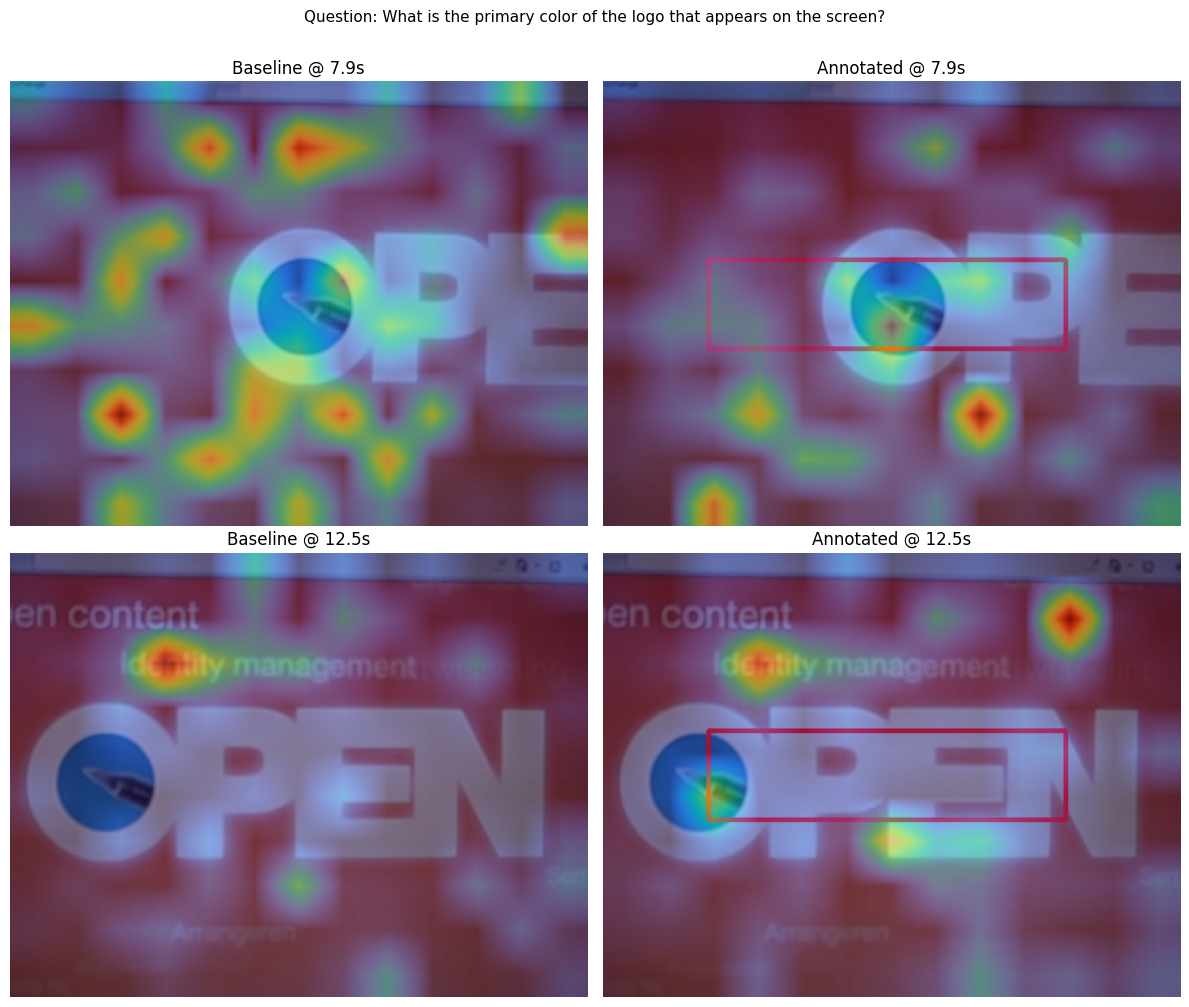

In [52]:
# Visualize: for each key frame, overlay the smoothed attention heatmap on the frame
# for both annotated and baseline conditions.

def normalize(amap):
    mn, mx = amap.min(), amap.max()
    return (amap - mn) / (mx - mn + 1e-9)

grid_thw_ann  = inputs_ann["image_grid_thw"].cpu()
grid_thw_base = inputs_base["image_grid_thw"].cpu()

OVERLAY_ALPHA = 0.5
CMAP = "turbo"

n_kf = len(kf_indices)
fig, axes = plt.subplots(n_kf, 2, figsize=(12, 5 * n_kf))
if n_kf == 1:
    axes = [axes]

for row, (merged_idx, kf_meta) in enumerate(zip(kf_indices, example["key_frames"])):
    t = kf_meta["time"]

    frame_ann  = item_ann["merged_frames"][merged_idx].permute(1, 2, 0).to(torch.uint8).numpy()
    frame_base = item_base["merged_frames"][merged_idx].permute(1, 2, 0).to(torch.uint8).numpy()

    amap_ann  = normalize(answer_to_frame_attn(attn_ann,  ans_indices_ann,  per_frame_vis_ann,  merged_idx, item_ann["merged_frames"],  grid_thw_ann))
    amap_base = normalize(answer_to_frame_attn(attn_base, ans_indices_base, per_frame_vis_base, merged_idx, item_base["merged_frames"], grid_thw_base))

    ax = axes[row]
    ax[0].imshow(frame_base)
    ax[0].imshow(amap_base, cmap=CMAP, alpha=OVERLAY_ALPHA, vmin=0, vmax=1)
    ax[0].set_title(f"Baseline @ {t}s"); ax[0].axis("off")

    ax[1].imshow(frame_ann)
    ax[1].imshow(amap_ann, cmap=CMAP, alpha=OVERLAY_ALPHA, vmin=0, vmax=1)
    ax[1].set_title(f"Annotated @ {t}s"); ax[1].axis("off")

plt.suptitle(f"Question: {example['question']}", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()